# MNIST outlier detection with IMSTE

Compare consensus outliers across embedding dimensions, then inspect the top 100 average LOF ranks.


In [5]:
%matplotlib inline

from pathlib import Path
import sys

repo_root = next(path for path in (Path.cwd(), *Path.cwd().parents)
                 if (path / 'imste').is_dir() and (path / 'notebooks' / 'src').is_dir())
sys.path[:0] = [str(repo_root), str(repo_root / 'notebooks' / 'src')]

import numpy as np
from sklearn.preprocessing import StandardScaler
from imste import IteratedMinimumSpanningTreeEmbedder
from high_dim_mst_gallery import load_mnist_family_dataset
from outlier_visualization import show_outlier_grid


## Load MNIST


In [6]:
SAMPLES_PER_CLASS = 5000
RANDOM_STATE = 42
DATASET = 'Fashion-MNIST'  # Also: 'MNIST' or 'Kuzushiji-MNIST' or 'Fashion-MNIST'

X_all, y_all = load_mnist_family_dataset(DATASET)
rng = np.random.default_rng(RANDOM_STATE)
selected = np.concatenate([
    rng.choice(np.flatnonzero(y_all == label), SAMPLES_PER_CLASS, replace=False)
    for label in np.unique(y_all)
])
rng.shuffle(selected)
X_images = np.asarray(X_all[selected], dtype=np.float32)
y = np.asarray(y_all[selected])
X = StandardScaler().fit_transform(X_images).astype(np.float32)


## Fit and score


In [7]:
K = 10
N_COMPONENTS = [5, 10, 30]
ESTIMATOR_PARAMS = {
    'n_components': 2,
    'n_msts': 15,
    'n_epochs': 200,
    'random_state': RANDOM_STATE,
    'device': 'auto',
}

mapper = IteratedMinimumSpanningTreeEmbedder(**ESTIMATOR_PARAMS)
embedding = mapper.fit_transform(X)
result = mapper.outliers(k=K, n_components=N_COMPONENTS)


## Plot consensus outliers and all ranks

Consensus images come first, followed by the top 100 samples ranked by average LOF.


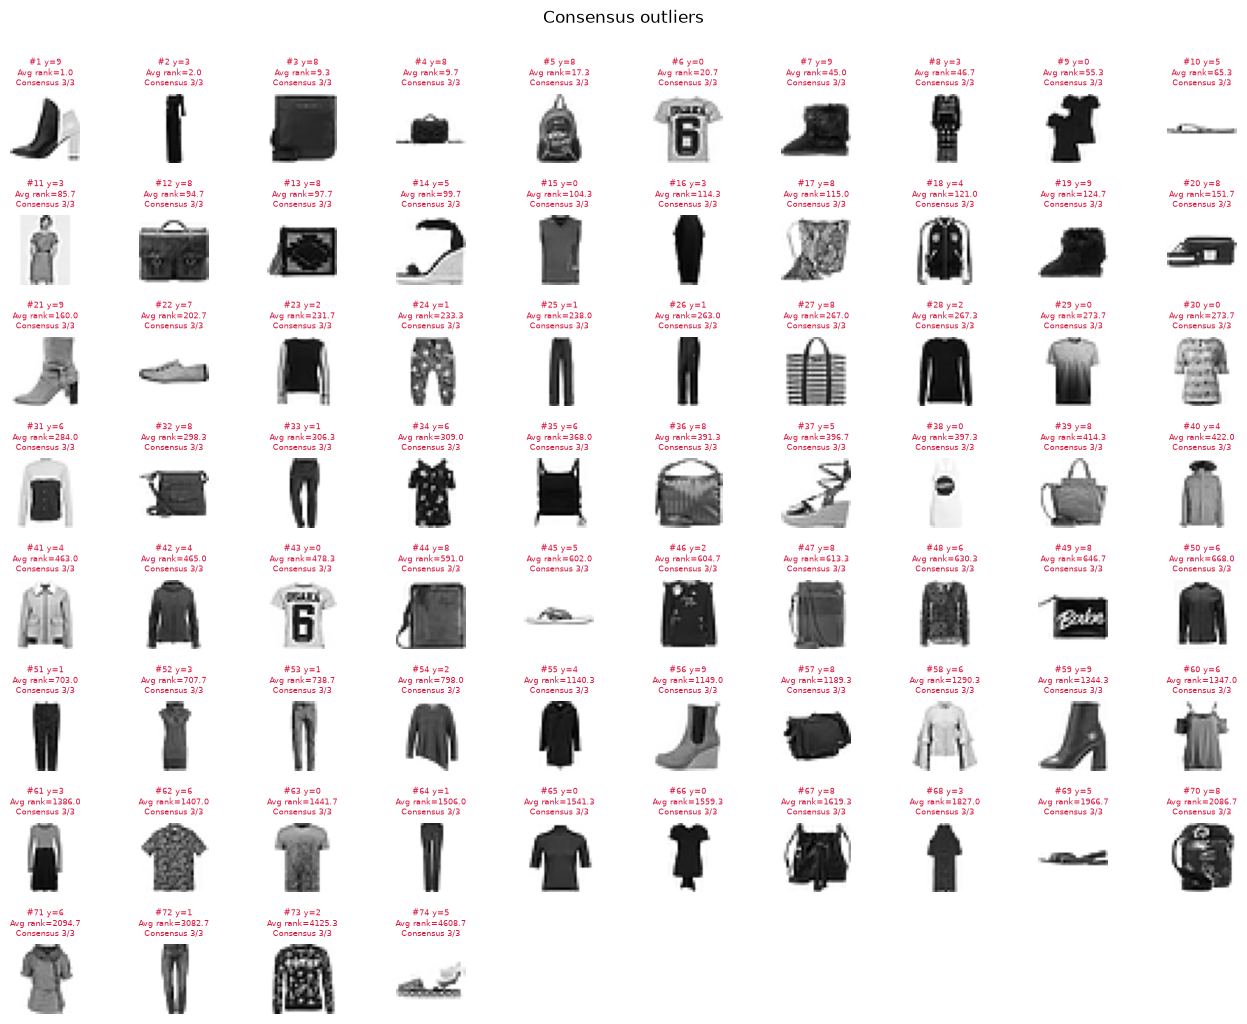

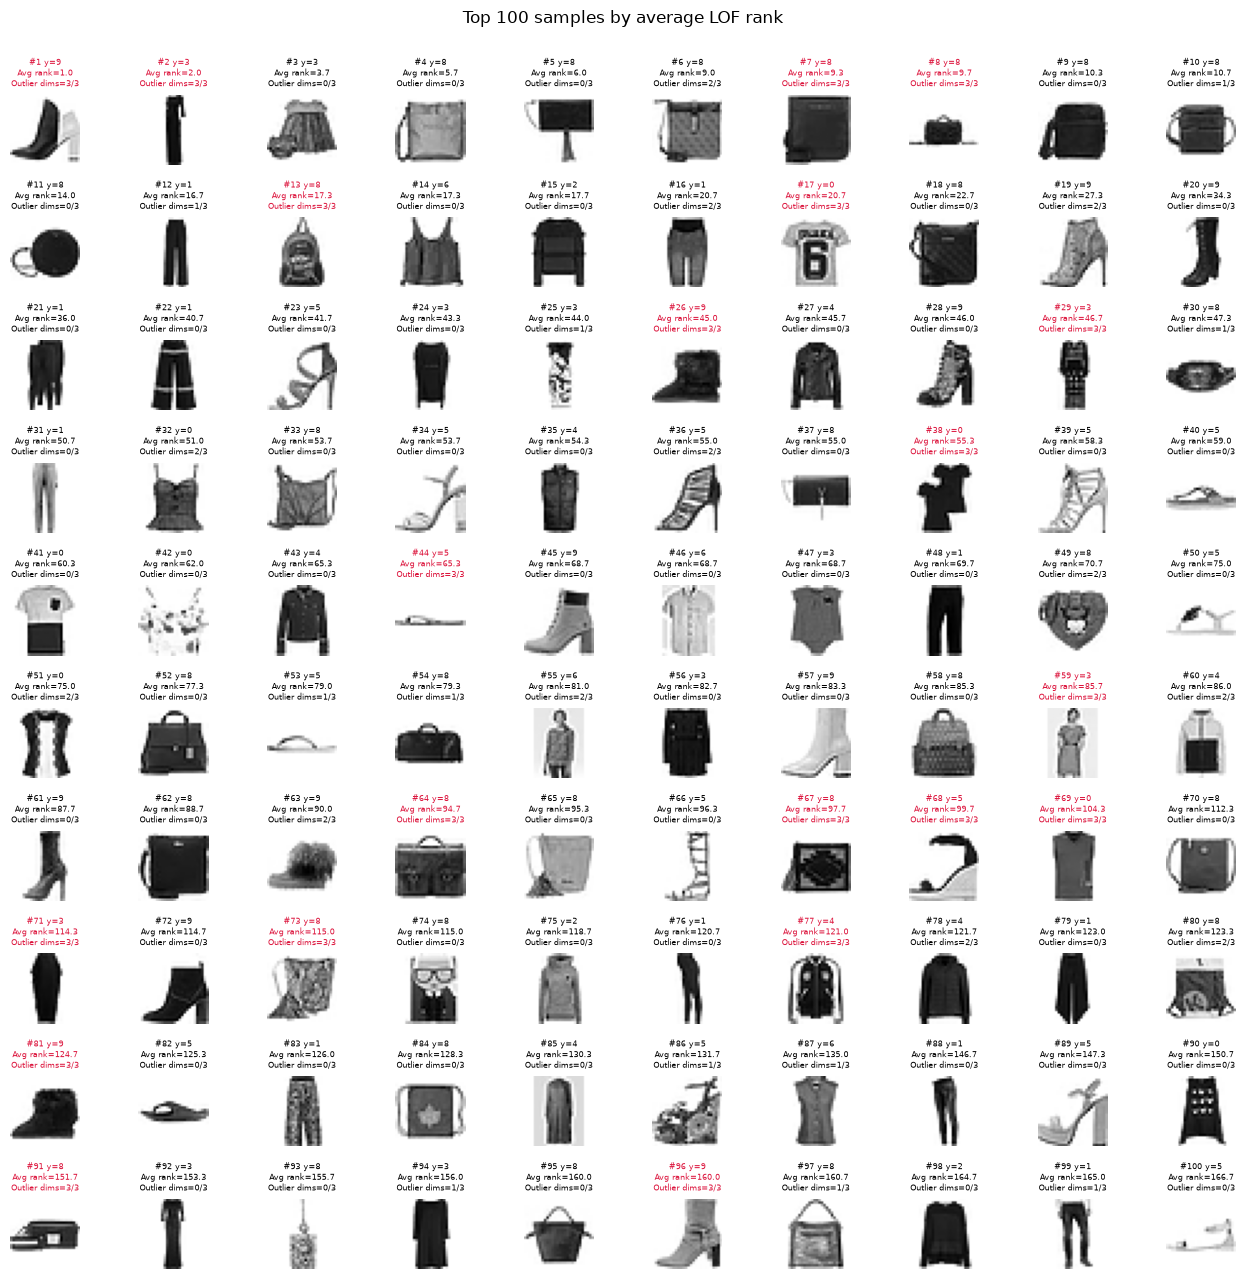

In [8]:
show_outlier_grid(X_images, y, result, result.outlier_indices,
                  'Consensus outliers', consensus=True)
show_outlier_grid(X_images, y, result, result.ranked_indices,
                  'Top 100 samples by average LOF rank')
